<a href="https://colab.research.google.com/github/ahzan457/Data-Science-Mini-Project/blob/main/Titanic_Data_Science_Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!

Dataset loaded successfully! Shape: (891, 15)

First 5 rows:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

--- MISSING VALUES CHECK ---
age            177
embarked         2
deck           688
embark_town      2
dtype: int64

Data

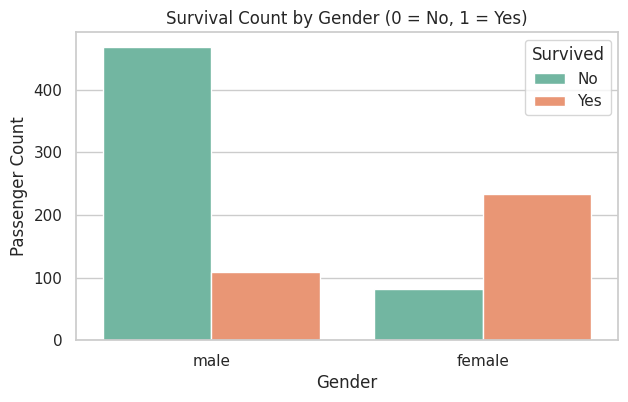

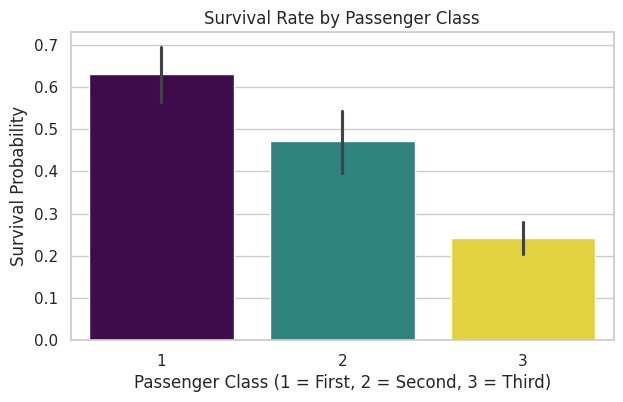

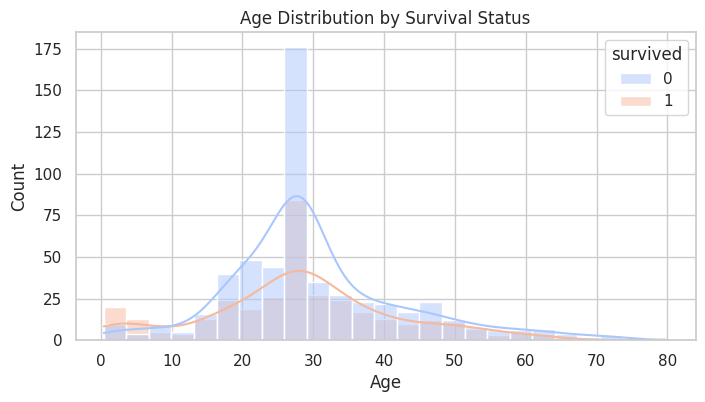

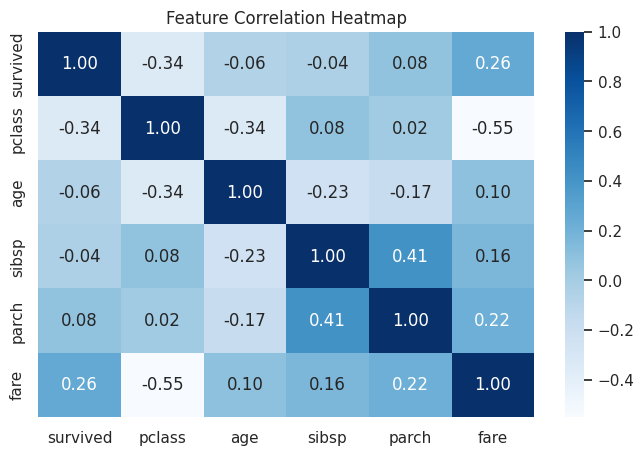


SUMMARY OF KEY FINDINGS:
1. Gender Impact: Females had a significantly higher survival rate (~74%) compared to males (~19%).
2. Class Disparity: 1st Class passengers had the highest survival probability (~63%), whereas 3rd Class had the lowest (~24%).
3. Age Factor: Young children (under age 10) showed a notably higher survival spike compared to young adults.
4. Fare Correlation: Higher ticket fares positively correlated with survival rate, reflecting better cabin class access.



In [1]:
# ==========================================
# MODULE 05: DATA SCIENCE MINI PROJECT
# Dataset: Titanic Survival Analysis (Public Dataset)
# ==========================================

# 1. IMPORT LIBRARIES
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

# 2. LOAD REAL-WORLD PUBLIC DATASET
df = sns.load_dataset('titanic')
print("\nDataset loaded successfully! Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# 3. DATA EXPLORATION & CLEANING
print("\n--- MISSING VALUES CHECK ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Cleaning: Fill missing 'age' with median, 'embarked' with mode, and drop 'deck' (too many missing values)
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df_clean = df.drop(columns=['deck'])

print("\nData cleaned! Remaining missing values:", df_clean.isnull().sum().sum())

# 4. STATISTICAL SUMMARY & INSIGHTS
print("\n--- KEY STATISTICAL INSIGHTS ---")
overall_survival = df_clean['survived'].mean() * 100
print(f"1. Overall Survival Rate: {overall_survival:.2f}%")

print("\n2. Survival Rate by Gender (%):")
print(df_clean.groupby('sex')['survived'].mean() * 100)

print("\n3. Survival Rate by Passenger Class (%):")
print(df_clean.groupby('pclass')['survived'].mean() * 100)

# 5. DATA VISUALIZATIONS

# Plot 1: Survival Count by Gender
plt.figure(figsize=(7, 4))
sns.countplot(x='sex', hue='survived', data=df_clean, palette='Set2')
plt.title('Survival Count by Gender (0 = No, 1 = Yes)')
plt.xlabel('Gender')
plt.ylabel('Passenger Count')
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

# Plot 2: Survival Rate by Passenger Class
plt.figure(figsize=(7, 4))
sns.barplot(
    x='pclass',
    y='survived',
    data=df_clean,
    palette='viridis',
    hue='pclass',
    legend=False,
)
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class (1 = First, 2 = Second, 3 = Third)')
plt.ylabel('Survival Probability')
plt.show()

# Plot 3: Age Distribution of Survivors vs Non-Survivors
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df_clean,
    x='age',
    hue='survived',
    bins=25,
    kde=True,
    palette='coolwarm',
)
plt.title('Age Distribution by Survival Status')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

# Plot 4: Correlation Heatmap
plt.figure(figsize=(8, 5))
numeric_cols = df_clean.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

# 6. SUMMARY OF FINDINGS
print("""
==========================================
SUMMARY OF KEY FINDINGS:
1. Gender Impact: Females had a significantly higher survival rate (~74%) compared to males (~19%).
2. Class Disparity: 1st Class passengers had the highest survival probability (~63%), whereas 3rd Class had the lowest (~24%).
3. Age Factor: Young children (under age 10) showed a notably higher survival spike compared to young adults.
4. Fare Correlation: Higher ticket fares positively correlated with survival rate, reflecting better cabin class access.
==========================================
""")